# Early Warning Signals (EWS) — Demo
This notebook demonstrates count-based rolling EWS on an irregular time series using your current `ews.py`.

**Contents**
1. Generate a synthetic *irregular* series
2. Run rolling EWS with moving-average detrending
3. Plot all core indicators across windows
4. Try optional detrenders (EWMA / Gaussian) with required parameters set

_Note:_ The notebook loads `/mnt/data/ews.py` directly from disk—edit and rerun to iterate.

In [4]:

import os, sys, types, importlib.util, numpy as np, pandas as pd
import matplotlib.pyplot as plt

EWS_PATH = "/Users/mrosen44/Documents/dev/narrativeClimate/dynClimToolkit/dynclim/features/temporal/ews.py"

def load_ews(path: str):
    spec = importlib.util.spec_from_file_location("ews_mod", path)
    mod = importlib.util.module_from_spec(spec)
    sys.modules["ews_mod"] = mod
    spec.loader.exec_module(mod)
    return mod

ews = load_ews(EWS_PATH)
ews


<module 'ews_mod' from '/Users/mrosen44/Documents/dev/narrativeClimate/dynClimToolkit/dynclim/features/temporal/ews.py'>

In [8]:
TEMP_PATH = "/Users/mrosen44/Documents/dev/narrativeClimate/dynClimToolkit/dynclim/features/temporal/temporal_features.py"

def load_ews(path: str):
    spec = importlib.util.spec_from_file_location("temp_mod", path)
    mod = importlib.util.module_from_spec(spec)
    sys.modules["temp_mod"] = mod
    spec.loader.exec_module(mod)
    return mod

temp = load_ews(TEMP_PATH)
temp

<module 'temp_mod' from '/Users/mrosen44/Documents/dev/narrativeClimate/dynClimToolkit/dynclim/features/temporal/temporal_features.py'>

## 1) Simulate an irregular series

In [5]:

rng = np.random.default_rng(10)
n = 900
waits = rng.exponential(scale=90.0, size=n)  # seconds
t = np.cumsum(waits)
timestamps = pd.to_datetime(t, unit="s")

phi = 0.65
e = rng.normal(scale=1.0, size=n)
x = np.zeros(n)
for i in range(1, n):
    x[i] = phi * x[i-1] + e[i]

trend = 0.0015 * t
values = trend + x

pd.DataFrame({"timestamp": timestamps, "value": values}).head()


,timestamp,value
0,1970-01-01 00:01:09.688887203,0.104533
1,1970-01-01 00:01:51.543762680,-1.317551
2,1970-01-01 00:04:40.985838876,-0.382233
3,1970-01-01 00:05:21.256851011,-1.870932
4,1970-01-01 00:10:04.824891439,-1.428038


In [ ]:
results_df.

## 2) Configure and run rolling EWS (count-based)
All `compute_*` flags are set to `True` to compute every indicator.

In [ ]:

cfg = ews.EWSConfig()

# Turn on every compute_* flag if present
for field in getattr(cfg, "__dataclass_fields__", {}):
    if field.startswith("compute_"):
        setattr(cfg, field, True)

# Detrend via moving average
if hasattr(cfg, "detrend"):
    cfg.detrend = "moving_average"
if hasattr(cfg, "ma_window"):
    cfg.ma_window = 19

out = ews.rolling_or_expanding_ews(
    values=values,
    timestamps=timestamps,
    window_size=41,
    step=30,
    mode="rolling",
    cfg=cfg
)
out.head()


,window_index,start_idx,end_idx,start_time,end_time,n_events,mean,variance,std,cv,acf1,ar1,return_rate,skew,kurtosis,spectral_ratio,spectral_slope,dfa_alpha
0,0,0,149,1970-01-01 00:01:09.688887203,1970-01-01 03:31:29.662445453,150,0.616378,5.869288,2.422661,3.930479,0.903921,0.958871,0.041129,1.856958,3.576090,94.650119,-1.625137,1.398608
1,1,30,179,1970-01-01 00:37:56.944342327,1970-01-01 04:10:04.767781426,150,0.878130,6.050375,2.459751,2.801123,0.901725,0.975079,0.024921,1.939059,4.560894,107.783464,-1.472476,1.302837
2,2,60,209,1970-01-01 01:24:57.698423408,1970-01-01 04:43:51.404884955,150,1.169035,9.150840,3.025036,2.587635,0.925502,0.994146,0.005854,2.015198,4.627365,141.006878,-1.594347,1.462733
3,3,90,239,1970-01-01 02:10:51.583175039,1970-01-01 05:21:57.318592605,150,1.370171,10.646052,3.262829,2.381330,0.931038,0.987018,0.012982,2.133617,5.219493,108.990226,-1.593117,1.451479
4,4,120,269,1970-01-01 02:49:24.632964532,1970-01-01 06:01:30.751479670,150,1.579494,14.185099,3.766311,2.384504,0.944788,1.016781,-0.016781,2.259290,5.397841,139.452597,-1.480302,1.470720


In [ ]:
temp_result = temp.compute_temporal_features(
   df =  pd.DataFrame({'values':values, 'timestamps':timestamps}),
   time_col = 'timestamps',
   window_size = 10,
   step = 1,
   unit = 's',
   method = 'kimjo2016_periodic',
   min_valid = 3,
   return_windows = True,
   compute_memory = True,
   memory_lag = 1,
   event_ids = 'eid'
)
pd.DataFrame(temp_result)

ValueError: Length of values (899) does not match length of index (1)

In [25]:
temp_result['rolling_burstiness']

,window_index,start_idx,end_idx,start_time,end_time,n_events,n_intervals,mean_dt,sd_dt,cv,r,b,M
0,0,0,9,1970-01-01 00:01:09.688887203,1970-01-01 00:14:29.798674677,10,9,88.901087,83.876505,0.943481,0.943481,0.039521,-0.589945
1,1,1,10,1970-01-01 00:01:51.543762680,1970-01-01 00:15:22.582836233,10,9,90.115453,83.263455,0.923964,0.923964,0.023936,-0.525875
2,2,2,11,1970-01-01 00:04:40.985838876,1970-01-01 00:15:43.870995240,10,9,73.653906,80.554238,1.093686,1.093686,0.153701,-0.450440
3,3,3,12,1970-01-01 00:05:21.256851011,1970-01-01 00:16:51.580121852,10,9,76.702586,79.748312,1.039708,1.039708,0.113806,-0.746824
4,4,4,13,1970-01-01 00:10:04.824891439,1970-01-01 00:17:48.699937567,10,9,51.541672,31.851502,0.617976,0.617976,-0.246488,-0.786109
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,886,895,1970-01-01 21:51:59.811202583,1970-01-01 22:04:43.527231832,10,9,84.857337,100.421817,1.183419,1.183419,0.217388,-0.245472
887,887,887,896,1970-01-01 21:56:04.978256925,1970-01-01 22:05:05.445853396,10,9,60.051955,83.987556,1.398582,1.398582,0.357945,-0.192984
888,888,888,897,1970-01-01 21:56:52.209181076,1970-01-01 22:06:51.627643679,10,9,66.602051,85.024594,1.276606,1.276606,0.280265,-0.231063
889,889,889,898,1970-01-01 21:57:08.439818287,1970-01-01 22:07:56.743279867,10,9,72.033718,83.174541,1.154661,1.154661,0.197324,-0.221905


## 3) Plot indicators

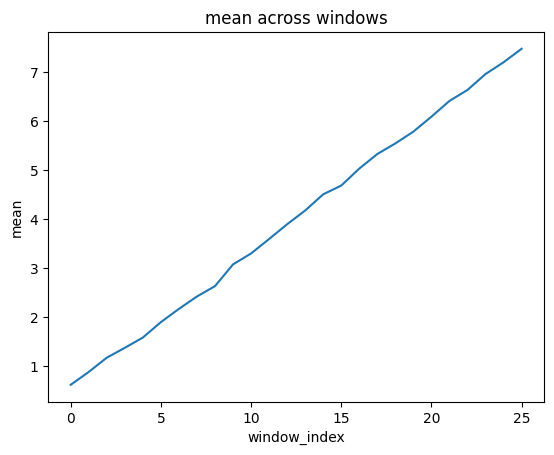

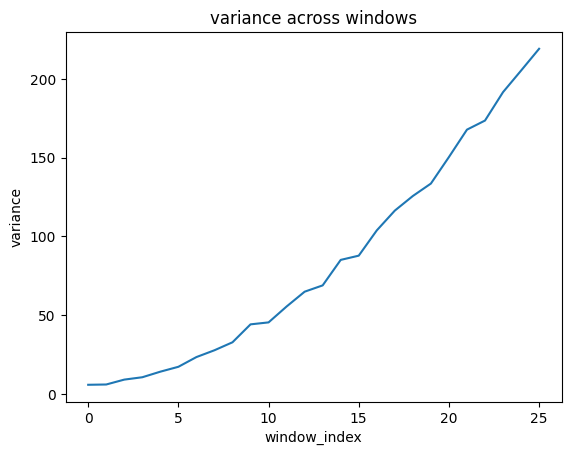

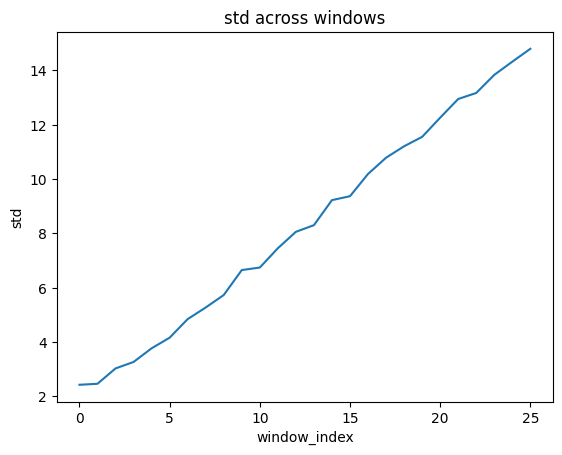

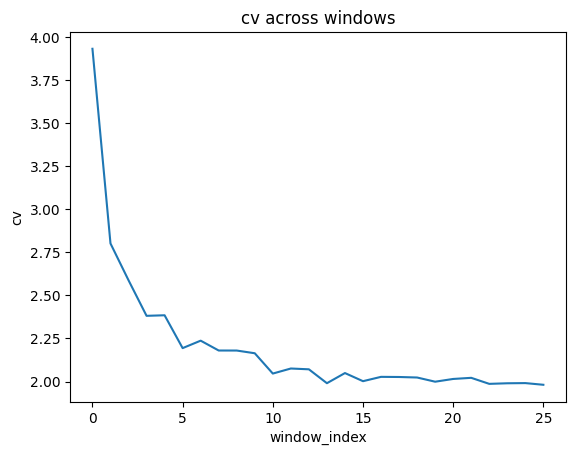

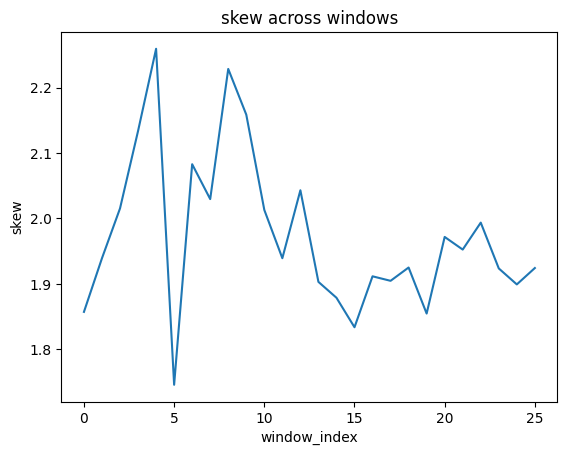

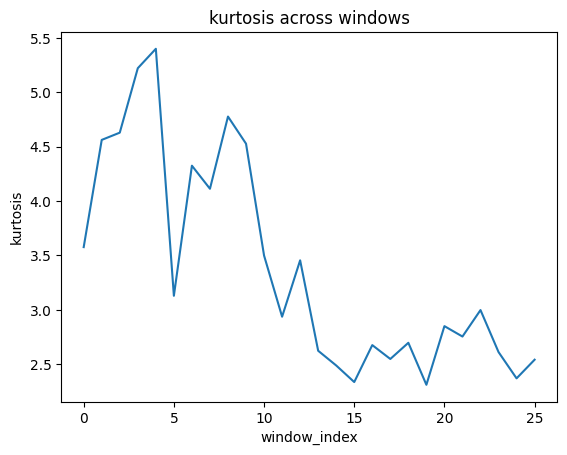

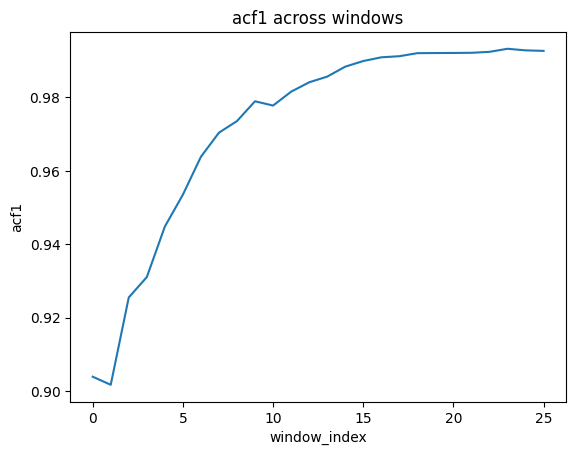

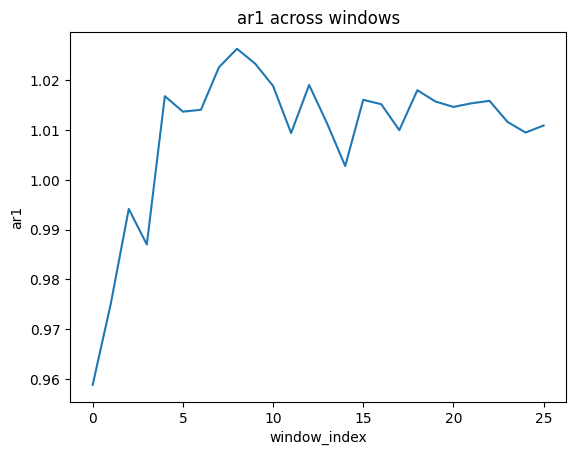

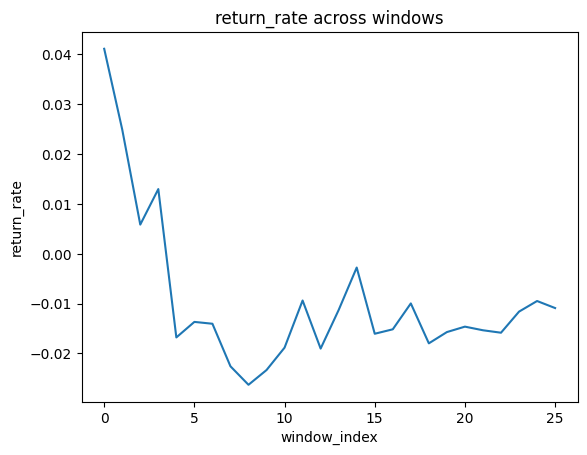

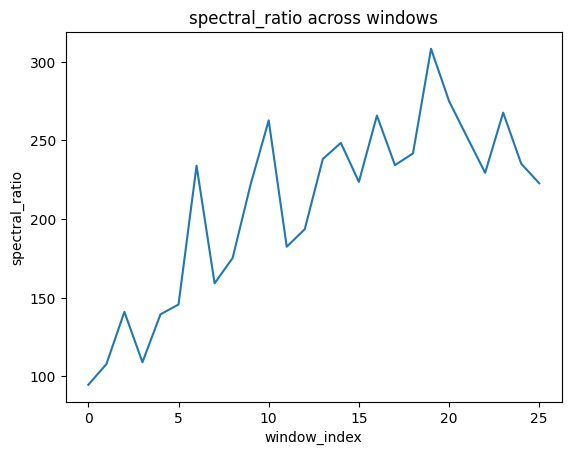

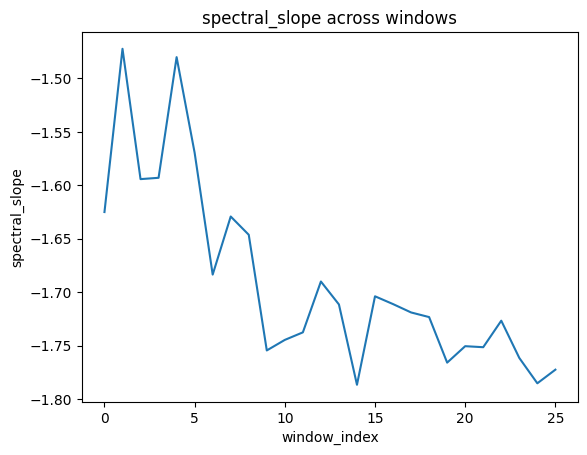

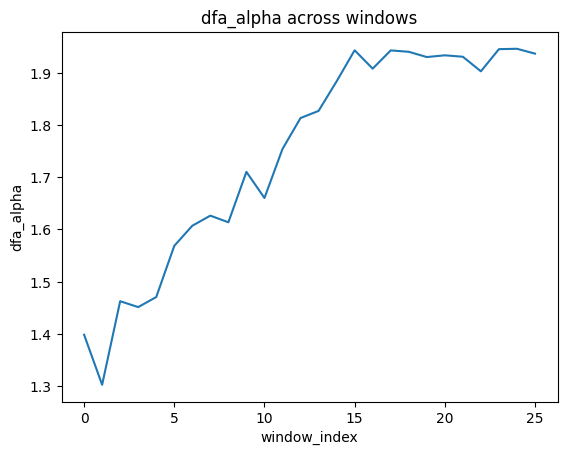

In [7]:

def plot_metric(col):
    plt.figure()
    plt.plot(out["window_index"], out[col])
    plt.title(f"{col} across windows")
    plt.xlabel("window_index")
    plt.ylabel(col)
    plt.show()

# Plot all columns that match computed metrics
for field in getattr(cfg, "__dataclass_fields__", {}):
    if field.startswith("compute_") and getattr(cfg, field, False):
        metric_name = field.replace("compute_", "")
        if metric_name in out.columns:
            plot_metric(metric_name)


## 4) Optional detrenders: EWMA & Gaussian
This cell sets the needed parameters so EWMA/Gaussian run without errors.

In [ ]:

if hasattr(ews, "_DETRENDS"):
    for method in ["ewma", "gaussian"]:
        if method in ews._DETRENDS:
            cfg2 = ews.EWSConfig()
            # Turn on all metrics
            for field in getattr(cfg2, "__dataclass_fields__", {}):
                if field.startswith("compute_"):
                    setattr(cfg2, field, True)

            if method == "ewma":
                # Provide both naming variants so your ews.py picks at least one
                if hasattr(cfg2, "detrend"):
                    cfg2.detrend = "ewma"
                for name in ["ewma_span", "span"]:
                    setattr(cfg2, name, 20)      # span ~20
                for name in ["ewma_alpha", "alpha"]:
                    setattr(cfg2, name, None)    # or set 0.1 if your code expects alpha
                for name in ["ewma_adjust", "adjust"]:
                    if hasattr(cfg2, name):
                        setattr(cfg2, name, True)

            elif method == "gaussian":
                if hasattr(cfg2, "detrend"):
                    cfg2.detrend = "gaussian"
                for name in ["gaussian_sigma", "sigma"]:
                    setattr(cfg2, name, 5.0)

            # Keep MA window harmlessly set
            if hasattr(cfg2, "ma_window"):
                cfg2.ma_window = 41

            out2 = ews.rolling_or_expanding_ews(
                values=values,
                timestamps=timestamps,
                window_size=150,
                step=30,
                mode="rolling",
                cfg=cfg2
            )

            if "ar1" in out2.columns:
                plt.figure()
                plt.plot(out2["window_index"], out2["ar1"])
                plt.title(f"AR(1) across windows ({method} detrend)")
                plt.xlabel("window_index")
                plt.ylabel("ar1")
                plt.show()
else:
    print("No _DETRENDS registry found in ews.py; skipping optional detrenders.")
